In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [16]:
import sys
print(sys.executable)


/home/nina/code/dskc25/.venv/bin/python


## Preamble

In [63]:
n = 1001

xmax = 0.2* 10**(-9)
xmin = -0.2* 10**(-9)
delx = (xmax - xmin) / (n - 1)
x = np.linspace(xmin, xmax, n)
# SI units
h_bar = 1.054 * 10**(-34) # J*s
m = 9.1 * 10**(-31) # kg
e = 1.6 * 10**(-19) # C
c = (h_bar**2) / (2 * m * delx**2 * e) # eV
print("c=", c, "eV")

c= 238434.9244505493 eV


## Making Hermitian Matrix 
### finding counter (bound states)

In [ ]:
V = np.zeros(n)

# Potential well
for i in range(n):
    if (np.abs(x[i]) <= 0.1 * 10**(-9)):   # '<' or '<=' depending on the definition of the well
        V[i] = -100
    else:
        V[i] = 0
pe = np.diag( V[1:n-1] ) # potential energy matrix. We are making a matrix whose axes are "state × state."
# Same for kinetic energy matrix. We are making a matrix whose axes are "state × state." The potential energy is diagonal in the position basis, 
# so we can just take the values of the potential at the positions corresponding to the states and put them on the diagonal of the matrix.

k = (-2 * np.eye(n-2)) + (np.eye((n-2), k=1)) + (np.eye((n-2), k=-1)) # kinetic energy matrix
ke = (-c) * k

H = ke + pe # Hamiltonian

eig_val, eig_vec = np.linalg.eigh(H) # eigenvalues and eigenvectors

print("size of H is ", H.shape, "size of K.E. is ", ke.shape, "size of P.E. is ", pe.shape, "size of eig_val is ", eig_val.shape, "size of eig_vec is ", eig_vec.shape)
counter = np.sum(eig_val < 0) # number of bound states
print("Number of bound states are ", counter," and their energies are ", eig_val[0:counter])


size of H is  (999, 999) size of K.E. is  (999, 999) size of P.E. is  (999, 999) size of eig_val is  (999,) size of eig_vec is  (999, 999)
Number of bound states are  4  and their energies are  [-93.45778416 -74.14907129 -43.34521289  -5.32717709]


# Plot

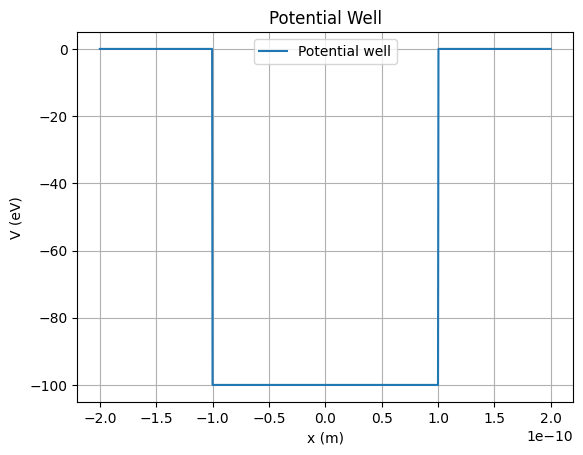

In [65]:
plt.plot(x, V, label="Potential well")
plt.xlabel("x (m)")
plt.ylabel("V (eV)")
plt.title("Potential Well")
plt.grid()
plt.legend()
plt.show()

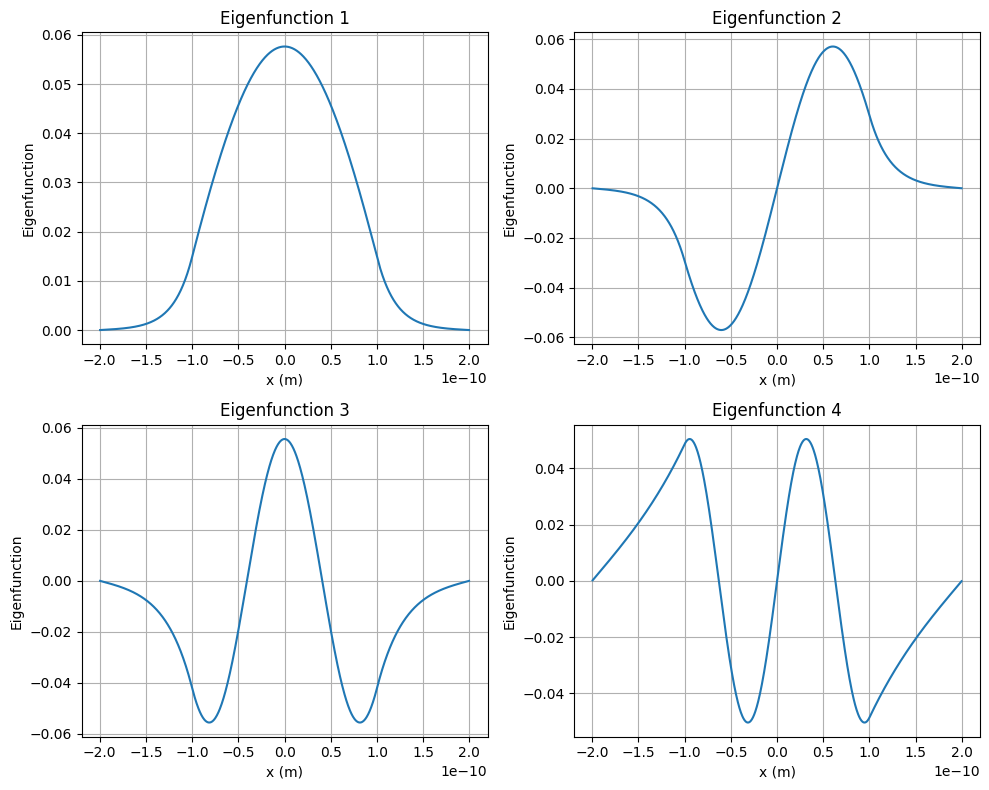

In [66]:
xnew = x[1:n-1] # new x values for plotting eigenfunctions
fig, ax = plt.subplots(2, 2, figsize=(10, 8))
for i in range(2):
    for j in range(2):
        ax[i,j].plot(xnew, eig_vec[:,i*2+j], label="Eigenfunction {}".format(i*2+j+1))
        ax[i,j].set_xlabel("x (m)")
        ax[i,j].set_ylabel("Eigenfunction")
        ax[i,j].set_title("Eigenfunction {}".format(i*2+j+1))
        ax[i,j].grid()
plt.tight_layout()
plt.show()

# Expectation value

In [ ]:
wf = np.zeros_like(eig_vec)

exp_x , exp_x2, exp_V = np.zeros(counter), np.zeros(counter), np.zeros(counter)
for i in range(counter):
    print("\nEigenvalue ", i+1, " is ", eig_val[i], " eV")
    psi = eig_vec[:,i]
    yp = psi**2 # probability density
    Norm_sq = np.trapezoid(yp, xnew) # normalization factor
    wf[:,i] = psi / np.sqrt(Norm_sq) # normalize eigenfunctions
    
    # expectation val. x
    ypp = wf[:,i] * xnew * wf[:,i] # probability density for expectation value of x
    exp_x[i] = np.trapezoid( ypp, xnew) # expectation value of x
    print("<x> = ", exp_x[i])
    
    # expectation val. x^2
    yppp = wf[:,i] * xnew**2 * wf[:,i] # probability density for expectation value of x^2
    exp_x2[i] = np.trapezoid( yppp, xnew) # expectation value of x^2
    print("<x^2> = ", exp_x2[i])
    
    # expectation val. V
    ypppp = wf[:,i] * V[1:n-1] * wf[:,i] # probability density for expectation value of V
    exp_V[i] = np.trapezoid( ypppp, xnew) # expectation value of V
    print("<V> = ", exp_V[i])
# ⟨U⟩n is not simply "the value of (U)" at one particular (x). It is a weighted average over the entire wavefunction


Eigenvalue  1  is  -93.45778416343869  eV
<x> =  -5.202190571134276e-25
<x^2> =  1.9278310777626503e-21
<V> =  -98.90345469571912

Eigenvalue  2  is  -74.14907129433391  eV
<x> =  -7.173206874483287e-25
<x^2> =  4.3085907975189875e-21
<V> =  -95.24119808581251

Eigenvalue  3  is  -43.34521288908082  eV
<x> =  -1.1502980393315541e-24
<x^2> =  5.278919895571303e-21
<V> =  -87.23737122686728

Eigenvalue  4  is  -5.3271770932026365  eV
<x> =  -1.0727498569047078e-24
<x^2> =  7.67756022849588e-21
<V> =  -66.99642783988843


In [68]:
diff_psi = np.zeros((n-3, counter))
psi_mid = np.zeros((n-3, counter))
for j in range(counter):  # diff_psi shape (n-3) x (counter)
    for i in range(n-3):
        diff_psi[i,j] = (wf[i+1,j] - wf[i,j]) / ( delx) 
        psi_mid[i,j] = (wf[i+1,j] + wf[i,j]) / 2

xmid = np.zeros(n-3) 
for i in range(n-3):
    xmid[i] = (xnew[i+1] + xnew[i]) / 2



diff2_psi = np.zeros((n-4, counter))

# psi_mid2 = wf[1:n-3]  # size of psi_mid2 is (n-4) x (counter) 
# print(psi_mid2.shape)   

psi_mid2 = np.zeros((n-4, counter))

for j in range(counter):  # j is the index for the eigenfunction, different states
    for i in range(n-4):
        diff2_psi[i,j] = (wf[i+1,j] - 2*wf[i,j] + wf[i-1,j]) / (delx**2)
        psi_mid2[i,j] = (psi_mid[i+1,j] + psi_mid[i,j]) /2
        
print(psi_mid2.shape, "  and  ", diff2_psi.shape) 

xmid2 = np.zeros(n-4)
for i in range(n-4):
    xmid2[i] = (xmid[i+1] + xmid[i]) / 2
    
        

(997, 4)   and   (997, 4)


In [69]:
# print("size of diff2_psi is ", diff2_psi.shape, " and size of psi is ", psi.shape)
# print("size of wf is ", wf.shape)
# print("size of psi_mid2 is ", psi_mid2.shape)

'''
Difference between psi and wf is that psi is the eigenfunction obtained from the Hamiltonian, while wf is the normalized eigenfunction. 
The normalization ensures that the total probability of finding the particle in the entire space is equal to 1.
'''
exp_p = np.zeros(counter)
exp_p2 = np.zeros(counter)

for i in range(counter):
    print("\nEigenvalue ", i+1, " is ", eig_val[i], " eV")
    
    yp = psi_mid[:,i] * diff_psi[:,i]
    print("yp shape is ", yp.shape, "xmid shape is ", xmid.shape)
    # <p> = - i h_bar (psi_mid*) d/dx (psi_mid) 
    exp_p[i] = -1 * h_bar * np.trapezoid( yp, xmid) # expectation value of p
    print("<p> = ", exp_p[i]) 
    
    
    yp = psi_mid2[:,i] * diff2_psi[:,i]
    # <p^2> = - h_bar^2 (psi_mid2*) d^2/dx^2 (psi_mid2) 
    # print(np.trapezoid( yp, xmid2))
    exp_p2[i] = - h_bar**2 * np.trapezoid( yp, xmid2) # expectation value of p
    print("<p^2> = ", exp_p2[i])
    


Eigenvalue  1  is  -93.45778416343869  eV
yp shape is  (998,) xmid shape is  (998,)
<p> =  -0.0
<p^2> =  1.5856522039448375e-48

Eigenvalue  2  is  -74.14907129433391  eV
yp shape is  (998,) xmid shape is  (998,)
<p> =  -2.5129318237304686e-41
<p^2> =  6.141218221446673e-48

Eigenvalue  3  is  -43.34521288908082  eV
yp shape is  (998,) xmid shape is  (998,)
<p> =  -1.0051727294921874e-40
<p^2> =  1.277851184197917e-47

Eigenvalue  4  is  -5.3271770932026365  eV
yp shape is  (998,) xmid shape is  (998,)
<p> =  -5.025863647460937e-41
<p^2> =  1.795426385757296e-47


## Ehrenfest theorem


In [70]:
exp_ke = (1/ (2*m*e)) * exp_p2  # in eV; <KE> = <p^2>/(2m) 

print(exp_ke.shape)

E = exp_ke + exp_V
for i in range(counter):
    print("\nEnergy eigenvalue for ", i+1, " state =", eig_val[i], " eV")
    print("<KE> + <PE> = ", E[i], " eV")

(4,)

Energy eigenvalue for  1  state = -93.45778416343869  eV
<KE> + <PE> =  -93.45822047887559  eV

Energy eigenvalue for  2  state = -74.14907129433391  eV
<KE> + <PE> =  -74.1518497978775  eV

Energy eigenvalue for  3  state = -43.34521288908082  eV
<KE> + <PE> =  -43.35511902226849  eV

Energy eigenvalue for  4  state = -5.3271770932026365  eV
<KE> + <PE> =  -5.340301955365902  eV


### Uncertainty ppl.

In [71]:
# For each state, we will obtain sigma_x, sigma_p, and the uncertainty product sigma_x * sigma_p.

var_x = exp_x2 - exp_x**2
sigma_x = np.sqrt(var_x)

var_y = exp_p2 - exp_p**2
sigma_p = np.sqrt(var_y)

sigma_xp = sigma_x * sigma_p

for i in range(counter):
    print("\nEigenvalue ", i+1, " is ", eig_val[i], " eV")
    print("var_x =", var_x[i],"; var_y =", var_y[i])
    print("sigma_x = ", sigma_x[i], "; sigma_p = ", sigma_p[i], "; sigma_x * sigma_p = ", sigma_xp[i])
print("\nh_bar / 2 = ", h_bar/2)

ratio = sigma_xp / (h_bar/2)
print("ratio of sigma_x * sigma_p to h_bar/2 is ", ratio)
print("The ratio increases with energy eigenvalue")


Eigenvalue  1  is  -93.45778416343869  eV
var_x = 1.9278310777626503e-21 ; var_y = 1.5856522039448375e-48
sigma_x =  4.3907073208796895e-11 ; sigma_p =  1.2592268278371603e-24 ; sigma_x * sigma_p =  5.528896451632728e-35

Eigenvalue  2  is  -74.14907129433391  eV
var_x = 4.3085907975189875e-21 ; var_y = 6.141218221446673e-48
sigma_x =  6.563985677558253e-11 ; sigma_p =  2.4781481435633894e-24 ; sigma_x * sigma_p =  1.6266528921217663e-34

Eigenvalue  3  is  -43.34521288908082  eV
var_x = 5.278919895571303e-21 ; var_y = 1.277851184197917e-47
sigma_x =  7.265617589421633e-11 ; sigma_p =  3.5747044412061774e-24 ; sigma_x * sigma_p =  2.597243546501123e-34

Eigenvalue  4  is  -5.3271770932026365  eV
var_x = 7.67756022849588e-21 ; var_y = 1.795426385757296e-47
sigma_x =  8.76216881171316e-11 ; sigma_p =  4.237247202792511e-24 ; sigma_x * sigma_p =  3.712747528782737e-34

h_bar / 2 =  5.27e-35
ratio of sigma_x * sigma_p to h_bar/2 is  [1.04912646 3.08662788 4.92835588 7.04506172]
The ratio 

## (a) Variation  in N

In [72]:
N = [5, 501, 1001, 2001, 3001]  # Different values of n to test
for i in range(len(N)):
    n = N[i]
    xmax = 0.2* 10**(-9)
    xmin = -0.2* 10**(-9)
    delx = (xmax - xmin) / (n - 1)
    x = np.linspace(xmin, xmax, n)
    c = (h_bar**2) / (2 * m * delx**2 * e) # eV
    print("\nn=", n, "\nc=", c, "eV")
    V = np.zeros(n)

    # Potential well
    for i in range(n):
        if (np.abs(x[i]) <= 0.1 * 10**(-9)):   # '<' or '<=' depending on the definition of the well
            V[i] = -100
        else:
            V[i] = 0
            
    pe = np.diag( V[1:n-1] ) # potential energy matrix
    ke = (-c) * ((-2 * np.eye(n-2)) + (np.eye((n-2), k=1)) + (np.eye((n-2), k=-1))) # kinetic energy matrix
    H = ke + pe # Hamiltonian
    
    eig_val, eig_vec = np.linalg.eigh(H) # eigenvalues and eigenvectors
    counter = np.sum(eig_val < 0) # number of bound states
    print("Number of bound states are ", counter," and their energies are ", eig_val[0:counter])

print("How sensitive are the bound states to the choice of n")


n= 5 
c= 3.8149587912087886 eV
Number of bound states are  3  and their energies are  [-97.76524888 -92.37008242 -86.97491596]

n= 501 
c= 59608.731112637324 eV


Number of bound states are  4  and their energies are  [-93.47981883 -74.23466869 -43.52368559  -5.56876247]

n= 1001 
c= 238434.9244505493 eV
Number of bound states are  4  and their energies are  [-93.45778416 -74.14907129 -43.34521289  -5.32717709]

n= 2001 
c= 953739.6978021972 eV
Number of bound states are  4  and their energies are  [-93.44681524 -74.10653765 -43.25678391  -5.20808625]

n= 3001 
c= 2145914.3200549437 eV
Number of bound states are  4  and their energies are  [-93.4431662  -74.09239947 -43.22742818  -5.16864163]
How sensitive are the bound states to the choice of n


## (b) Varying depth of potential well

In [62]:
V1 = np.zeros(n)
V2 = np.zeros(n)
V3 = np.zeros(n)

# Potential well
for i in range(n):
    if (np.abs(x[i]) <= 0.1 * 10**(-9)):   # '<' or '<=' depending on the definition of the well
        V1[i] = -50
        V2[i] = -100
        V3[i] = -200
    else:
        V1[i] = 0
        V2[i] = 0
        V3[i] = 0
        
pe1 = np.diag( V1[1:n-1] ) # potential energy matrix
pe2 = np.diag( V2[1:n-1] )
pe3 = np.diag( V3[1:n-1] )

k = (-c)* ( (-2 * np.eye(n-2)) + (np.eye((n-2), k=1)) + (np.eye((n-2), k=-1)) )# kinetic energy matrix
# ke = (-c) * k # kinetic energy matrix
print(pe1)
print(ke)

H1 = ke + pe1 # Hamiltonian
H2 = ke + pe2
H3 = ke + pe3

eig_val1, eig_vec1 = np.linalg.eigh(H1) # eigenvalues and eigenvectors
eig_val2, eig_vec2 = np.linalg.eigh(H2)
eig_val3, eig_vec3 = np.linalg.eigh(H3)

print("size of H1 is ", H1.shape, "size of K.E. is ", ke.shape, "size of P.E.1 is ", pe1.shape, "size of eig_val1 is ", eig_val1.shape, "size of eig_vec1 is ", eig_vec1.shape)

counter1 = np.sum(eig_val1 < 0) # number of bound states
counter2 = np.sum(eig_val2 < 0) 
counter3 = np.sum(eig_val3 < 0) 

print("Number of bound states for V1= -50 eV ", counter1," and their energies are ", eig_val1[0:counter1])
print("Number of bound states for V1= -100 eV ", counter2," and their energies are ", eig_val2[0:counter2])
print("Number of bound states for V1= -200 eV ", counter3," and their energies are ", eig_val3[0:counter3])


[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
[[ 4291828.64010989 -2145914.32005494       -0.         ...
        -0.               -0.               -0.        ]
 [-2145914.32005494  4291828.64010989 -2145914.32005494 ...
        -0.               -0.               -0.        ]
 [      -0.         -2145914.32005494  4291828.64010989 ...
        -0.               -0.               -0.        ]
 ...
 [      -0.               -0.               -0.         ...
   4291828.64010989 -2145914.32005494       -0.        ]
 [      -0.               -0.               -0.         ...
  -2145914.32005494  4291828.64010989 -2145914.32005494]
 [      -0.               -0.               -0.         ...
        -0.         -2145914.32005494  4291828.64010989]]
size of H1 is  (2999, 2999) size of K.E. is  (2999, 2999) size of P.E.1 is  (2999, 2999) size of eig_val1 is  (2999,) size of eig_vec1 i

## (c) Variation in well width

In [ ]:
# 30th Sept
width_val = [0.1, 0.2, 0.4 ]
n=1001 
for i in width_val:
    a = (10 **(-9))* i / 2
    print("\nWidth of the well is ", 2*a, " m")
    xmin = -2*a
    xmax = 2*a
    delx = (xmax - xmin) / (n - 1)
    x = np.linspace(xmin, xmax, n)
    c = (h_bar**2) / (2 * m * delx**2 * e) # eV
    print("\nn=", n, "\nc=", c, "eV")
    V = np.zeros(n)

    # Potential well
    for i in range(n):
        if (np.abs(x[i]) <= 0.1 * 10**(-9)):   # '<' or '<=' depending on the definition of the well
            V[i] = -100
        else:
            V[i] = 0
            
    pe = np.diag( V[1:n-1] ) # potential energy matrix
    ke = (-c) * ((-2 * np.eye(n-2)) + (np.eye((n-2), k=1)) + (np.eye((n-2), k=-1))) # kinetic energy matrix
    H = ke + pe # Hamiltonian
    
    eig_val, eig_vec = np.linalg.eigh(H) # eigenvalues and eigenvectors
    counter = np.sum(eig_val < 0) # number of bound states
    print("Number of bound states are ", counter," and their energies are ", eig_val[0:counter])



Width of the well is  1.0000000000000002e-10  m

n= 1001 
c= 953739.6978021972 eV
Number of bound states are  3  and their energies are  [-90.58697422 -62.3479898  -15.28332542]

Width of the well is  2.0000000000000003e-10  m

n= 1001 
c= 238434.9244505493 eV
Number of bound states are  4  and their energies are  [-93.45778416 -74.14907129 -43.34521289  -5.32717709]

Width of the well is  4.0000000000000007e-10  m

n= 1001 
c= 59608.731112637324 eV
Number of bound states are  4  and their energies are  [-93.48003213 -74.23682127 -43.55048124  -6.50919862]
